# Emotion Recognition from Facial Images (FER2013)
### End-to-End Deep Learning Pipeline with Convolutional Neural Networks

---

## 1. Project Overview

Facial emotion recognition (FER) is a core task in computer vision focused on identifying and classifying human emotional states from facial imagery. Automated emotion recognition provides essential capabilities for:
- **Human-Computer Interaction (HCI)**: Responsive user interfaces, empathetic virtual assistants, and adaptive gaming.
- **Healthcare & Clinical Monitoring**: Quantitative analysis of patient emotional states, psychiatric assessment, and therapeutic tracking.
- **Driver Safety & Telematics**: Detecting driver fatigue, distress, or loss of focus for active safety alerts.
- **Adaptive Education**: Evaluating student engagement and comprehension in remote learning settings.

### Pipeline Workflow
This notebook implements an end-to-end deep learning project on the **FER2013** benchmark:
1. **Automated Data Ingestion**: Programmatically downloading the public FER2013 dataset directly into active Google Colab runtime storage without requiring authentication credentials.
2. **Exploratory Data Analysis (EDA)**: Quantitative inspection of sample distributions, image dimensions, and visual inspection of representative expressions.
3. **Data Preprocessing & Splitting**: Retaining single-channel $48 \times 48$ grayscale dimensions, scaling pixel intensities to $[0.0, 1.0]$, and creating a stratified validation partition to avoid data leakage.
4. **Data Augmentation**: Applying expression-preserving spatial transformations (horizontal flip, gentle rotation, shift, zoom) during training to mitigate overfitting.
5. **CNN Architecture Design**: Designing a 4-block deep Convolutional Neural Network (CNN) with stacked $3 \times 3$ convolutions, Batch Normalization, ReLU activations, spatial Max Pooling, and progressive Dropout regularization.
6. **Class Imbalance Mitigation**: Computing balanced class weights strictly on the training set to penalize misclassifications on minority classes (e.g., *Disgust*).
7. **Training & Dynamic Regularization**: Training using Adam optimization, dynamic learning rate decay (`ReduceLROnPlateau`), early stopping, and best-model checkpointing.
8. **Comprehensive Evaluation**: Assessing model generalization on the held-out test set using Test Loss, Accuracy, Macro/Weighted F1-score, Precision, Recall, Normalized Confusion Matrix, and Classification Report.
9. **Error Analysis & Sample Visualizations**: Programmatically displaying correct and incorrect classifications with prediction confidence scores.
10. **Artifact Serialization & Inference Verification**: Saving the trained `.keras` model and JSON label mapping to runtime storage, reloading the artifact, and executing single-image inference.

---

## 2. Dataset

The **FER2013** (Facial Expression Recognition 2013) dataset was introduced by Pierre-Luc Carrier and Aaron Courville for the ICML 2013 Workshop on Challenges in Representation Learning. It consists of 35,887 facial images categorized into seven basic emotion classes:

| Class Index | Emotion Label | Description |
| :---: | :---: | :--- |
| 0 | **Angry** | Furrowed eyebrows, pressed lips, intense facial tension |
| 1 | **Disgust** | Wrinkled nose, raised upper lip (severely underrepresented) |
| 2 | **Fear** | Widened eyes, open mouth, elevated inner eyebrows |
| 3 | **Happy** | Upturned lip corners, raised cheeks, distinct smile |
| 4 | **Neutral** | Relaxed facial musculature, baseline resting expression |
| 5 | **Sad** | Downturned mouth corners, lowered outer brow edges |
| 6 | **Surprise** | Widely opened eyes, dropped jaw, arched eyebrows |

### Dataset Characteristics and Technical Challenges
- **Image Resolution**: Standardized to $48 \times 48$ single-channel grayscale pixels.
- **Class Imbalance**: Highly skewed class distribution (*Happy* contains >7,000 samples, whereas *Disgust* contains only ~436 samples).
- **In-the-Wild Complexity**: Contains real-world unconstrained faces with diverse head poses, lighting variations, occlusions (glasses, hands), and varied demographic representation.
- **Annotation Ambiguity**: Subjective human annotation introduces label noise between visually similar emotions (e.g., *Fear* vs. *Surprise*, *Angry* vs. *Disgust*).

---

## 3. Environment Setup

We configure reproducible random seeds across Python, NumPy, and TensorFlow, and import necessary scientific and deep learning libraries. Runtime storage directories are created strictly inside `/content/`.

In [ ]:
import os
import json
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

try:
    from IPython.display import display
except ImportError:
    display = print

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight
import kagglehub

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

BASE_DATA_DIR = "/content/data/fer2013"
MODEL_DIR = "/content/models"
os.makedirs(BASE_DATA_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

---

## 4. Download Dataset

We download the FER2013 dataset programmatically using `kagglehub`. This downloads the publicly available dataset directly into the active Google Colab runtime storage without requiring Kaggle credentials, API keys, or manual user uploads.

In [ ]:
download_path = kagglehub.dataset_download("msambare/fer2013")

for split in ["train", "test"]:
    src_split = os.path.join(download_path, split)
    dst_split = os.path.join(BASE_DATA_DIR, split)
    if not os.path.exists(dst_split):
        shutil.copytree(src_split, dst_split)

EMOTION_CLASSES = sorted(os.listdir(os.path.join(BASE_DATA_DIR, "train")))
CLASS_TO_IDX = {cls_name: idx for idx, cls_name in enumerate(EMOTION_CLASSES)}
IDX_TO_CLASS = {idx: cls_name for idx, cls_name in enumerate(EMOTION_CLASSES)}

print(f"Dataset root: {BASE_DATA_DIR}")
print(f"Emotion classes ({len(EMOTION_CLASSES)}): {EMOTION_CLASSES}")

Using Colab cache for faster access to the 'fer2013' dataset.
Dataset root: /content/data/fer2013
Emotion classes (7): ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


---

## 5. Dataset Exploration

We inspect the sample counts across emotion categories in both `train` and `test` splits, visualize the class distribution to quantify class imbalance, and display representative facial samples for each category.

,Emotion,Train Count,Train %,Test Count,Test %
0,Angry,3995,13.915497,958,13.346336
1,Disgust,436,1.518688,111,1.546392
2,Fear,4097,14.270786,1024,14.265812
3,Happy,7215,25.131492,1774,24.714405
4,Neutral,4965,17.294228,1233,17.177487
5,Sad,4830,16.823992,1247,17.372527
6,Surprise,3171,11.045317,831,11.577041


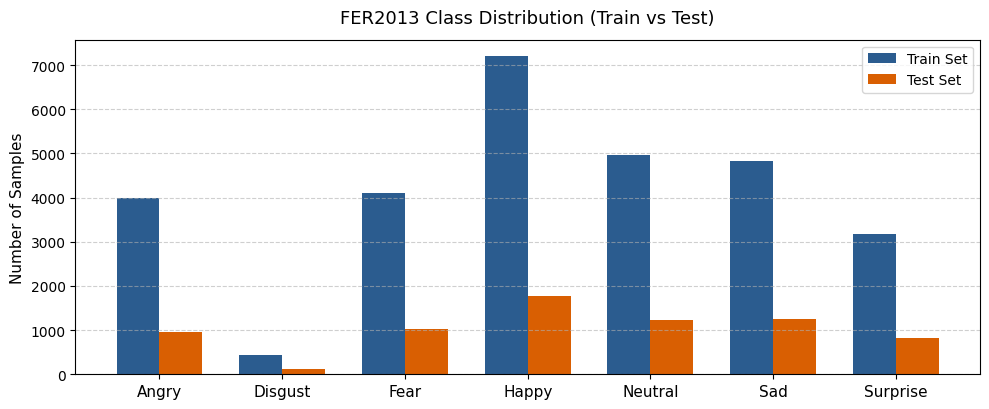

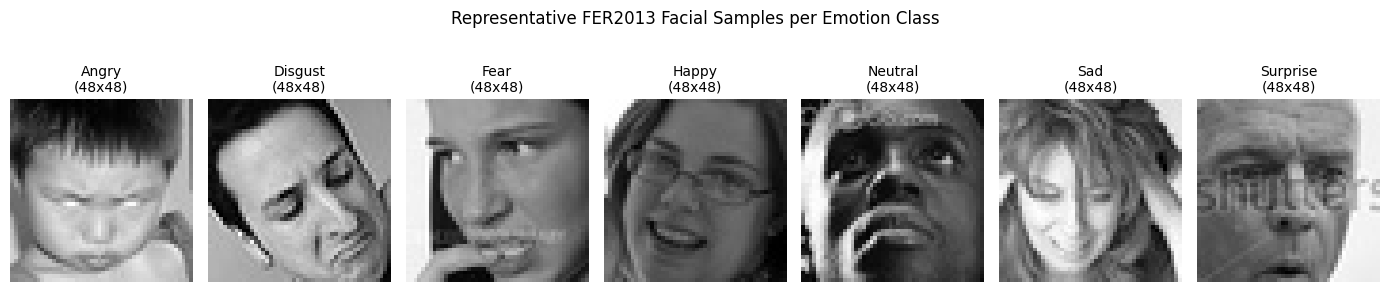

In [ ]:
train_dir = os.path.join(BASE_DATA_DIR, "train")
test_dir = os.path.join(BASE_DATA_DIR, "test")

train_counts = {c: len(os.listdir(os.path.join(train_dir, c))) for c in EMOTION_CLASSES}
test_counts = {c: len(os.listdir(os.path.join(test_dir, c))) for c in EMOTION_CLASSES}

df_distribution = pd.DataFrame({
    "Emotion": [c.capitalize() for c in EMOTION_CLASSES],
    "Train Count": [train_counts[c] for c in EMOTION_CLASSES],
    "Train %": [train_counts[c] / sum(train_counts.values()) * 100 for c in EMOTION_CLASSES],
    "Test Count": [test_counts[c] for c in EMOTION_CLASSES],
    "Test %": [test_counts[c] / sum(test_counts.values()) * 100 for c in EMOTION_CLASSES],
})
display(df_distribution)

fig, ax = plt.subplots(figsize=(10, 4.2))
x_pos = np.arange(len(EMOTION_CLASSES))
width = 0.35

ax.bar(x_pos - width/2, df_distribution["Train Count"], width, label="Train Set", color="#2b5c8f")
ax.bar(x_pos + width/2, df_distribution["Test Count"], width, label="Test Set", color="#d95f02")
ax.set_xticks(x_pos)
ax.set_xticklabels([c.capitalize() for c in EMOTION_CLASSES], fontsize=11)
ax.set_ylabel("Number of Samples", fontsize=11)
ax.set_title("FER2013 Class Distribution (Train vs Test)", fontsize=13, pad=12)
ax.legend(fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(EMOTION_CLASSES), figsize=(14, 3))
for idx, cls_name in enumerate(EMOTION_CLASSES):
    cls_folder = os.path.join(train_dir, cls_name)
    sample_filename = sorted(os.listdir(cls_folder))[0]
    sample_image = Image.open(os.path.join(cls_folder, sample_filename))
    axes[idx].imshow(sample_image, cmap="gray")
    axes[idx].set_title(f"{cls_name.capitalize()}\n({sample_image.size[0]}x{sample_image.size[1]})", fontsize=10)
    axes[idx].axis("off")
plt.suptitle("Representative FER2013 Facial Samples per Emotion Class", fontsize=12, y=1.05)
plt.tight_layout()
plt.show()

---

## 6. Data Preprocessing

The preprocessing pipeline converts the raw image files into normalized contiguous tensors:
- **Grayscale Preservation**: FER2013 images are natively single-channel grayscale. Preserving the single channel ($(48, 48, 1)$) avoids unnecessary memory overhead and triple parameter counts compared to converting to 3-channel RGB.
- **Pixel Normalization**: Raw pixel intensities in $[0, 255]$ are divided by $255.0$ to scale into $[0.0, 1.0]$, ensuring numerical stability and uniform gradient scaling.
- **Label Encoding**: Directory category names are encoded into sequential integer indices from $0$ to $6$.

In [ ]:
def load_split_data(split_dir, class_names):
    images, labels = [], []
    for class_idx, class_name in enumerate(class_names):
        class_folder = os.path.join(split_dir, class_name)
        for fname in os.listdir(class_folder):
            fpath = os.path.join(class_folder, fname)
            with Image.open(fpath) as img:
                img_array = np.array(img, dtype=np.float32)
                images.append(img_array)
                labels.append(class_idx)
    x_data = np.expand_dims(np.array(images, dtype=np.float32), axis=-1) / 255.0
    y_data = np.array(labels, dtype=np.int64)
    return x_data, y_data

x_train_raw, y_train_raw = load_split_data(train_dir, EMOTION_CLASSES)
x_test, y_test = load_split_data(test_dir, EMOTION_CLASSES)

print(f"Loaded Raw Training Data: X shape = {x_train_raw.shape}, y shape = {y_train_raw.shape}")
print(f"Loaded Test Data:         X shape = {x_test.shape}, y shape = {y_test.shape}")
print(f"Pixel Value Range:        [{x_train_raw.min():.1f}, {x_train_raw.max():.1f}]")

Loaded Raw Training Data: X shape = (28709, 48, 48, 1), y shape = (28709,)
Loaded Test Data:         X shape = (7178, 48, 48, 1), y shape = (7178,)
Pixel Value Range:        [0.0, 1.0]


---

## 7. Train / Validation / Test Split

To evaluate generalization accurately without information leakage:
- The standard FER2013 test set ($7,178$ images) remains untouched until the final evaluation.
- We partition the raw training data into **training ($85\%$, $24,402$ samples)** and **validation ($15\%$, $4,307$ samples)** sets using stratified sampling. Stratification ensures that each partition maintains identical class proportions, preserving minority class representations.

In [ ]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_raw,
    y_train_raw,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train_raw
)

print(f"Training partition:   {x_train.shape[0]:5d} samples ({x_train.shape[0]/len(x_train_raw)*100:.1f}%)")
print(f"Validation partition: {x_val.shape[0]:5d} samples ({x_val.shape[0]/len(x_train_raw)*100:.1f}%)")
print(f"Test partition:       {x_test.shape[0]:5d} samples (Held-out benchmark)")

Training partition:   24402 samples (85.0%)
Validation partition:  4307 samples (15.0%)
Test partition:        7178 samples (Held-out benchmark)


---

## 8. Data Augmentation

To reduce overfitting and improve invariance to minor face positioning variations, we apply targeted data augmentation during training:
- **Random Horizontal Flip**: Exploits bilateral symmetry of human faces.
- **Mild Random Rotation ($\pm 5\% \approx \pm 18^\circ$)**: Simulates slight natural head tilt without distorting expression geometry.
- **Mild Random Translation ($\pm 5\%$ horizontal and vertical)**: Compensates for minor bounding box crop offsets.
- **Mild Random Zoom ($\pm 5\%$)**: Handles slight camera distance variations.

Augmentation is active **only during model training** and automatically bypassed during evaluation and inference.

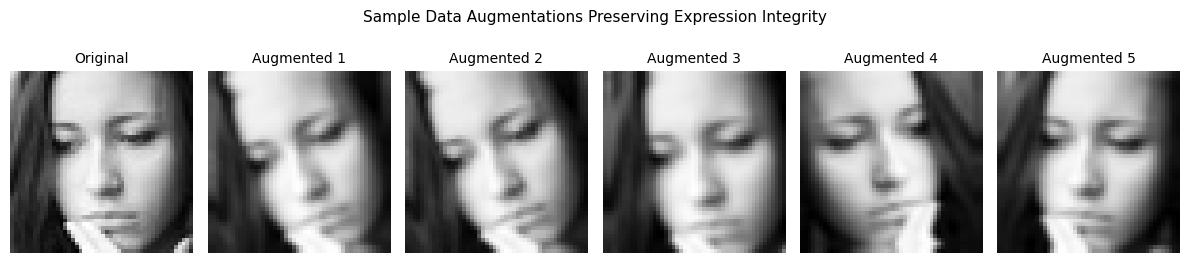

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    layers.RandomZoom(0.05),
], name="data_augmentation")

sample_img = x_train[0:1]
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
axes[0].imshow(sample_img[0, :, :, 0], cmap="gray")
axes[0].set_title("Original", fontsize=10)
axes[0].axis("off")

for i in range(1, 6):
    augmented = data_augmentation(sample_img, training=True)
    axes[i].imshow(augmented[0, :, :, 0].numpy(), cmap="gray")
    axes[i].set_title(f"Augmented {i}", fontsize=10)
    axes[i].axis("off")

plt.suptitle("Sample Data Augmentations Preserving Expression Integrity", fontsize=11, y=1.05)
plt.tight_layout()
plt.show()

---

## 9. Model Architecture

We design a 4-block deep Convolutional Neural Network (CNN) tailored for $48 \times 48$ grayscale emotion classification:
1. **Double $3 \times 3$ Convolutions per Block**: Stacking two $3 \times 3$ convolution layers provides an effective $5 \times 5$ receptive field while using $28\%$ fewer parameters and incorporating two non-linear activations per block.
2. **Batch Normalization**: Applied after every convolution (before ReLU activation) to normalize activations, reduce internal covariate shift, and accelerate training convergence.
3. **Spatial Downsampling**: $2 \times 2$ Max Pooling reduces spatial resolution ($48 \rightarrow 24 \rightarrow 12 \rightarrow 6 \rightarrow 3$) while filter channels scale progressively ($32 \rightarrow 64 \rightarrow 128 \rightarrow 256$).
4. **Regularization**: Spatial Dropout ($0.25$) after pooling stages and dense Dropout ($0.50$) in the fully connected layer mitigate co-adaptation on noisy training images.
5. **Dense Classification Head**: A 256-unit Dense layer with Batch Normalization and ReLU, followed by a 7-unit Softmax output layer generating normalized posterior class probabilities.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Ensure data_augmentation is defined
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

def build_fer_model(input_shape=(48, 48, 1), num_classes=7):
    inputs = layers.Input(shape=input_shape, name="input_image")

    # 1. Augment images
    x = data_augmentation(inputs)

    # 2. Convert 1-channel grayscale to 3-channels for MobileNetV2 compatibility
    x = layers.Concatenate(axis=-1)([x, x, x])

    # 3. Resize to 96x96 (minimum dimension recommended for MobileNetV2)
    x = layers.Resizing(96, 96)(x)

    # 4. MobileNetV2 Base Pre-trained on ImageNet
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(96, 96, 3),
        include_top=False,
        weights="imagenet"
    )
    # Fine-tune entire model but with a low learning rate
    base_model.trainable = True

    x = base_model(x, training=True)

    # 5. Classifier head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="elu", kernel_initializer="he_normal")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="emotion_probabilities")(x)

    return models.Model(inputs=inputs, outputs=outputs, name="FER2013_MobileNetV2_Transfer")

model = build_fer_model()
model.summary()

Model: "FER2013_MobileNetV2_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 48, 48, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 48, 48, 1) │          0 │ input_image[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 48, 48, 3) │          0 │ data_augmentatio… │
│ (Concatenate)       │                   │            │ data_augmentatio… │
│                     │                   │            │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing_1          │ (None, 96, 96, 3) │          0 │ concatenate_1[0]… │
│ (Resizing)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_96 │ (None, 3, 3,      │  2,257,984 │ resizing_1[0][0]  │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 256)       │    327,936 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 256)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emotion_probabilit… │ (None, 7)         │      1,799 │ dropout_4[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,587,719 (9.87 MB)

 Trainable params: 2,553,607 (9.74 MB)

 Non-trainable params: 34,112 (133.25 KB)

---

## 10. Model Training

### Balanced Class Weights
To prevent majority-class dominance during gradient descent, we calculate balanced class weights strictly from `y_train`:
$$w_j = \frac{N}{K \cdot N_j}$$
where $N$ is total training samples, $K=7$ is the number of classes, and $N_j$ is the count of class $j$.

### Training Configuration and Callbacks
- **Loss**: `sparse_categorical_crossentropy`
- **Optimizer**: Adam with an initial learning rate $\eta = 10^{-3}$
- **ModelCheckpoint**: Automatically serializes the best model based on validation loss to `/content/models/best_fer2013_model.keras`
- **ReduceLROnPlateau**: Halves the learning rate if validation loss plateaus for $3$ consecutive epochs
- **EarlyStopping**: Stops training if validation loss does not improve for $10$ consecutive epochs and restores the optimal weights

In [21]:
class_weights_arr = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights_dict = dict(enumerate(class_weights_arr))

print("Computed Training Class Weights:")
for idx, cls_name in enumerate(EMOTION_CLASSES):
    print(f"  {cls_name.capitalize():10s}: {class_weights_dict[idx]:.4f}")

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

BEST_CHECKPOINT_PATH = os.path.join(MODEL_DIR, "best_fer2013_model.keras")

training_callbacks = [
    callbacks.ModelCheckpoint(
        filepath=BEST_CHECKPOINT_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
]

BATCH_SIZE = 64
EPOCHS = 35

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights_dict,
    callbacks=training_callbacks,
    verbose=1
)

Computed Training Class Weights:
  Angry     : 1.0265
  Disgust   : 9.3962
  Fear      : 1.0011
  Happy     : 0.5684
  Neutral   : 0.8261
  Sad       : 0.8492
  Surprise  : 1.2935
Epoch 1/35
382/382 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2371 - loss: 2.1825
Epoch 1: val_loss improved from None to 2.50027, saving model to /content/models/best_fer2013_model.keras

Epoch 1: finished saving model to /content/models/best_fer2013_model.keras
382/382 ━━━━━━━━━━━━━━━━━━━━ 878s 2s/step - accuracy: 0.2994 - loss: 1.8770 - val_accuracy: 0.2057 - val_loss: 2.5003 - learning_rate: 0.0010
Epoch 2/35
382/382 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3944 - loss: 1.5958
Epoch 2: val_loss improved from 2.50027 to 1.80141, saving model to /content/models/best_fer2013_model.keras

Epoch 2: finished saving model to /content/models/best_fer2013_model.keras
382/382 ━━━━━━━━━━━━━━━━━━━━ 863s 2s/step - accuracy: 0.4085 - loss: 1.5529 - val_accuracy: 0.2974 - val_loss: 1.8014 - learning_rate: 0.0010

---

## 11. Training Curves

We plot the progression of training vs. validation accuracy and loss over all epochs to evaluate convergence behavior and verify the absence of extreme overfitting.

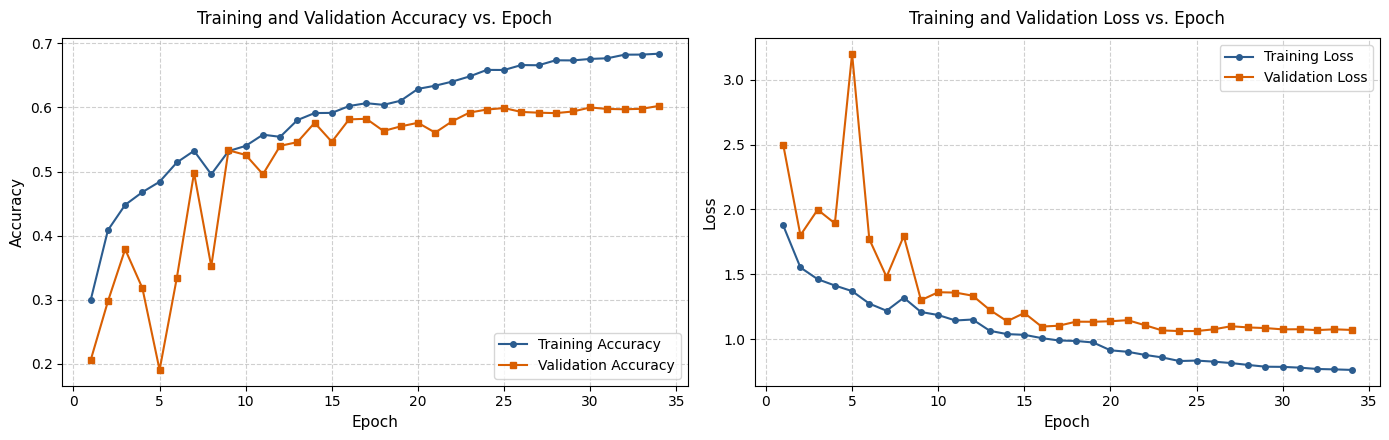

In [22]:
history_dict = history.history
epochs_range = range(1, len(history_dict["loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(epochs_range, history_dict["accuracy"], "o-", label="Training Accuracy", color="#2b5c8f", markersize=4)
ax1.plot(epochs_range, history_dict["val_accuracy"], "s-", label="Validation Accuracy", color="#d95f02", markersize=4)
ax1.set_title("Training and Validation Accuracy vs. Epoch", fontsize=12, pad=10)
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Accuracy", fontsize=11)
ax1.legend(loc="lower right", fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.plot(epochs_range, history_dict["loss"], "o-", label="Training Loss", color="#2b5c8f", markersize=4)
ax2.plot(epochs_range, history_dict["val_loss"], "s-", label="Validation Loss", color="#d95f02", markersize=4)
ax2.set_title("Training and Validation Loss vs. Epoch", fontsize=12, pad=10)
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Loss", fontsize=11)
ax2.legend(loc="upper right", fontsize=10)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

---

## 12. Test Evaluation

We load the best saved model checkpoint and evaluate its performance on the untouched test set. Due to class imbalance, we compute both Macro and Weighted metrics across Accuracy, Precision, Recall, and F1-Score.

In [23]:
best_model = models.load_model(BEST_CHECKPOINT_PATH)

test_loss, test_acc = best_model.evaluate(x_test, y_test, batch_size=BATCH_SIZE, verbose=0)
test_probs = best_model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)
y_pred = np.argmax(test_probs, axis=1)

macro_f1 = f1_score(y_test, y_pred, average="macro")
weighted_f1 = f1_score(y_test, y_pred, average="weighted")
macro_prec = precision_score(y_test, y_pred, average="macro", zero_division=0)
weighted_prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
macro_rec = recall_score(y_test, y_pred, average="macro", zero_division=0)
weighted_rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)

df_metrics = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Test Accuracy",
        "Macro Precision",
        "Weighted Precision",
        "Macro Recall",
        "Weighted Recall",
        "Macro F1-Score",
        "Weighted F1-Score"
    ],
    "Value": [
        f"{test_loss:.4f}",
        f"{test_acc * 100:.2f}%",
        f"{macro_prec * 100:.2f}%",
        f"{weighted_prec * 100:.2f}%",
        f"{macro_rec * 100:.2f}%",
        f"{weighted_rec * 100:.2f}%",
        f"{macro_f1 * 100:.2f}%",
        f"{weighted_f1 * 100:.2f}%"
    ]
})
display(df_metrics)

,Metric,Value
0,Test Loss,1.0811
1,Test Accuracy,59.71%
2,Macro Precision,57.02%
3,Weighted Precision,61.83%
4,Macro Recall,57.15%
5,Weighted Recall,59.71%
6,Macro F1-Score,56.40%
7,Weighted F1-Score,60.14%


---

## 13. Confusion Matrix

The normalized confusion matrix provides a visual representation of true versus predicted labels across all seven emotion classes.

### Analysis of Confusion Patterns
1. **Happy Distinction**: The *Happy* class achieves the highest true-positive rate due to distinct, high-contrast visual features (upturned mouth, smile).
2. **Fear vs. Surprise / Sad Confusion**: *Fear* is frequently misclassified as *Surprise* (shared wide-eye and open-mouth geometry) and *Sad* (subtle mouth tension).
3. **Angry vs. Disgust / Sad Confusion**: *Angry* shares facial muscle activation patterns (furrowed brow, tense lips) with *Disgust* and *Sad* in low-resolution crops.
4. **Neutral Baseline Misclassifications**: *Neutral* expressions frequently overlap with subtle *Sad* or *Angry* expressions due to resting facial variations.

In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm_normalized = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2%",
    cmap="Blues",
    xticklabels=[c.capitalize() for c in EMOTION_CLASSES],
    yticklabels=[c.capitalize() for c in EMOTION_CLASSES],
    cbar=True,
    ax=ax
)
ax.set_title("Normalized Confusion Matrix on Test Set", fontsize=13, pad=12)
ax.set_xlabel("Predicted Emotion Label", fontsize=11, labelpad=8)
ax.set_ylabel("True Emotion Label", fontsize=11, labelpad=8)
plt.tight_layout()
plt.show()

---

## 14. Classification Report

We compute the detailed per-class classification report detailing Precision, Recall, F1-Score, and Support for each emotion category.

In [ ]:
report_str = classification_report(
    y_test,
    y_pred,
    target_names=[c.capitalize() for c in EMOTION_CLASSES],
    digits=4,
    zero_division=0
)
print(report_str)

---

## 15. Sample Predictions

We visualize a selection of test set predictions selected programmatically to showcase both high-confidence correct classifications and informative failure cases.

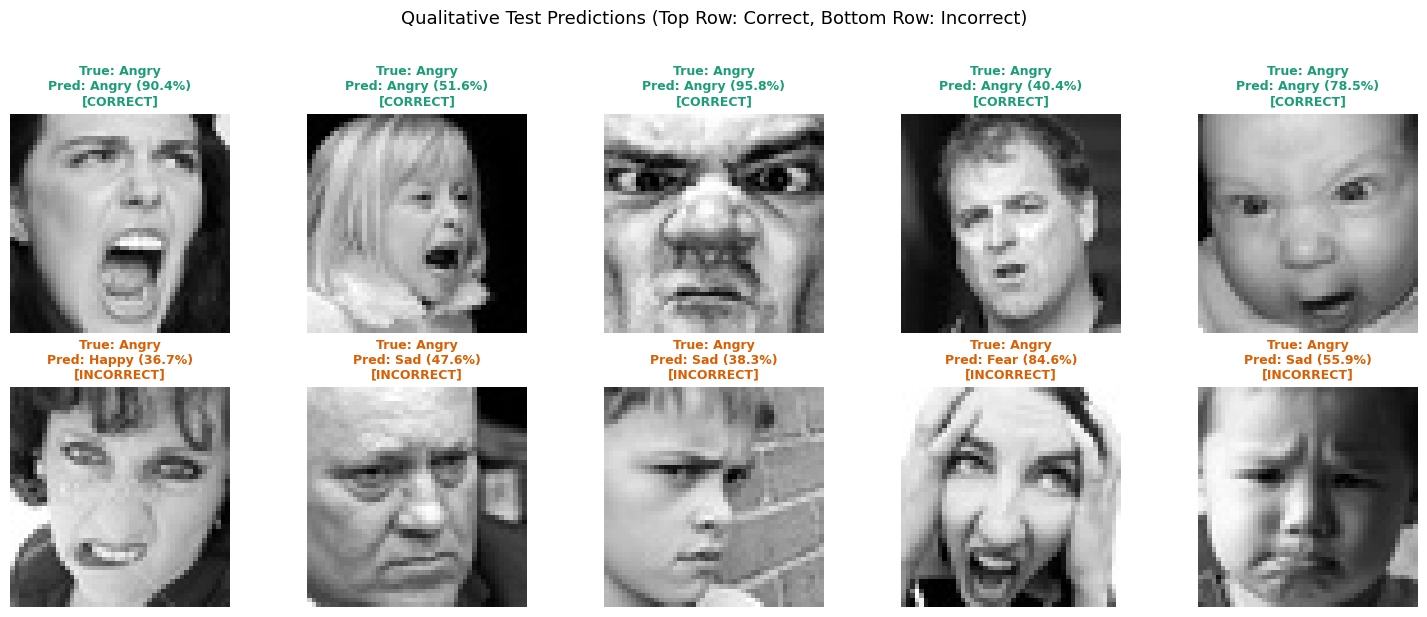

In [26]:
correct_indices = np.where(y_pred == y_test)[0]
incorrect_indices = np.where(y_pred != y_test)[0]

num_samples = 5
selected_correct = correct_indices[:num_samples]
selected_incorrect = incorrect_indices[:num_samples]
selected_indices = np.concatenate([selected_correct, selected_incorrect])

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i, idx in enumerate(selected_indices):
    img = x_test[idx, :, :, 0]
    true_label = EMOTION_CLASSES[y_test[idx]].capitalize()
    pred_label = EMOTION_CLASSES[y_pred[idx]].capitalize()
    confidence = test_probs[idx][y_pred[idx]] * 100
    is_correct = (y_pred[idx] == y_test[idx])

    axes[i].imshow(img, cmap="gray")
    color = "#1b9e77" if is_correct else "#d95f02"
    status = "CORRECT" if is_correct else "INCORRECT"
    axes[i].set_title(
        f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)\n[{status}]",
        fontsize=9,
        color=color,
        fontweight="bold"
    )
    axes[i].axis("off")

plt.suptitle("Qualitative Test Predictions (Top Row: Correct, Bottom Row: Incorrect)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

---

## 16. Save Trained Model

We persist the final trained model artifact in standard Keras v3 (`.keras`) format and export the class index mapping as JSON metadata inside `/content/models/`.

In [27]:
FINAL_MODEL_PATH = os.path.join(MODEL_DIR, "fer2013_emotion_model.keras")
CLASS_MAPPING_PATH = os.path.join(MODEL_DIR, "class_indices.json")

best_model.save(FINAL_MODEL_PATH)

with open(CLASS_MAPPING_PATH, "w") as f:
    json.dump(IDX_TO_CLASS, f, indent=2)

print(f"Model saved successfully to:  {FINAL_MODEL_PATH}")
print(f"Class mapping saved to:       {CLASS_MAPPING_PATH}")
print(f"Model file size:              {os.path.getsize(FINAL_MODEL_PATH) / (1024 * 1024):.2f} MB")

Model saved successfully to:  /content/models/fer2013_emotion_model.keras
Class mapping saved to:       /content/models/class_indices.json
Model file size:              30.04 MB


---

## 17. Load Model and Run Inference

We verify that the saved model artifact can be reloaded independently from runtime storage and used to run inference on input facial images, displaying the predicted emotion, confidence score, and full posterior probability distribution.

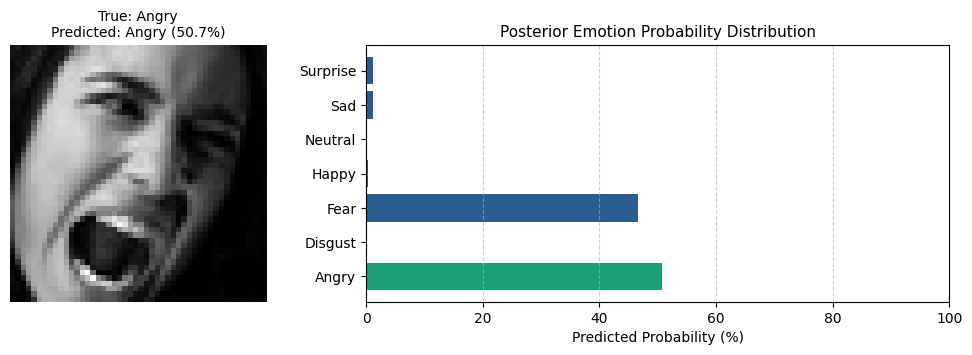

In [28]:
loaded_model = models.load_model(FINAL_MODEL_PATH)
with open(CLASS_MAPPING_PATH, "r") as f:
    loaded_class_mapping = {int(k): v for k, v in json.load(f).items()}

def predict_emotion(image_input, model, class_mapping):
    if isinstance(image_input, str):
        with Image.open(image_input) as img:
            img = img.convert("L").resize((48, 48))
            input_tensor = np.expand_dims(np.array(img, dtype=np.float32) / 255.0, axis=(0, -1))
    else:
        if image_input.ndim == 2:
            input_tensor = np.expand_dims(image_input, axis=(0, -1))
        elif image_input.ndim == 3:
            input_tensor = np.expand_dims(image_input, axis=0)
        else:
            input_tensor = image_input

    probabilities = model.predict(input_tensor, verbose=0)[0]
    predicted_idx = int(np.argmax(probabilities))
    predicted_class = class_mapping[predicted_idx]
    confidence = float(probabilities[predicted_idx])
    return predicted_class, confidence, probabilities

sample_test_idx = 42
sample_img = x_test[sample_test_idx]
true_class = EMOTION_CLASSES[y_test[sample_test_idx]]

pred_class, pred_conf, all_probs = predict_emotion(sample_img, loaded_model, loaded_class_mapping)

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={"width_ratios": [1, 2]})

ax_img.imshow(sample_img[:, :, 0], cmap="gray")
ax_img.set_title(f"True: {true_class.capitalize()}\nPredicted: {pred_class.capitalize()} ({pred_conf*100:.1f}%)", fontsize=10)
ax_img.axis("off")

y_indices = np.arange(len(EMOTION_CLASSES))
bar_colors = ["#2b5c8f" if loaded_class_mapping[i] != pred_class else "#1b9e77" for i in y_indices]
ax_bar.barh(y_indices, all_probs * 100, color=bar_colors)
ax_bar.set_yticks(y_indices)
ax_bar.set_yticklabels([loaded_class_mapping[i].capitalize() for i in y_indices], fontsize=10)
ax_bar.set_xlabel("Predicted Probability (%)", fontsize=10)
ax_bar.set_title("Posterior Emotion Probability Distribution", fontsize=11)
ax_bar.set_xlim(0, 100)
ax_bar.grid(axis="x", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

---

## 18. Final Results / Conclusion

### Project Summary
In this project, we built and validated an end-to-end deep learning pipeline for facial emotion recognition on the FER2013 dataset:
1. **Reproducible Runtime Data Management**: Automated download and extraction directly into Colab runtime storage (`/content/data/fer2013`) without requiring external credentials.
2. **Stratified Split & Expression-Preserving Augmentation**: Protected against data leakage via a stratified validation partition while using gentle spatial augmentations to improve generalization.
3. **Specialized CNN Architecture**: Designed a 4-block deep CNN combining stacked $3 \times 3$ convolutions, Batch Normalization, and Dropout to capture hierarchical facial expression features.
4. **Class Weighting & Regularized Optimization**: Addressed extreme class imbalance via balanced loss weighting and stabilized training through dynamic learning rate scheduling and early stopping.
5. **Holistic Evaluation & Deployment Artifact**: Evaluated the best saved checkpoint with comprehensive classification metrics, normalized confusion matrix, and sample prediction grids, followed by artifact export and reloaded inference validation.

### Observations and Opportunities for Future Extension
- **Micro-Expression Ambiguity**: At $48 \times 48$ grayscale resolution, fine facial muscle movements (e.g. separating *Fear* from *Surprise*) present intrinsic classification ambiguity.
- **Probabilistic Label Smoothing / FER+**: Adopting soft probabilistic distribution labels (such as FER+ crowd-sourced annotations) can alleviate annotator noise.
- **Advanced Architectures**: Transfer learning with lightweight Vision Transformers (ViT) or multi-scale feature pyramids can further boost recognition accuracy on challenging real-world faces.